# 1C. 예측모형 비교 — 검증 구간까지

**과제**: 예측 시점(원점) t에서 부품별 **앞으로 7일(t ~ t+6) 신고 건수 합계**를 맞힌다. 정비 부품 발주와 인력 배치에 쓰는 단위다.

**이 노트북이 답하려는 질문**
1. 나이브("다음 주 = 지난주")보다 얼마나 나은가? 모든 모형을 같은 원점·같은 정보·같은 지표로 비교한다.
2. 그 개선은 어디서 나오는가 — 대여량 예측인가, 신고율 모형인가?
3. 복잡한 모형(LightGBM, 딥러닝)이 단순한 구조(대여량 예측 × 신고율)보다 나은가?
4. 개입·환경 변수와 더위·얼었다 녹은 날은 넣는 편이 나은가? (넣은 것과 뺀 것 비교)
5. 날씨 예보가 틀릴 때 얼마나 나빠지는가?

**지키는 규칙**
- 학습은 2021-04-08 ~ 2023-12-25 원점, 비교는 **검증 구간(2024-01-01 ~ 12-25)**에서만 한다.
- **테스트 구간(2025 ~)은 이 노트북에서 예측도 채점도 하지 않는다.** 검증에서 고른 모형을 고정한 뒤, 사람이 승인하면 한 번만 연다.
- 원점 t에서 쓸 수 있는 것: t−1일까지의 관측값, 미래 7일의 달력, 미래 7일의 날씨 **예보**. 미래의 대여량·신고는 쓰지 않는다.

**날씨 시나리오**

| | 미래 7일의 날씨 | 뜻 |
|---|---|---|
| A | 실제 관측값 | 완벽한 예보가 있을 때의 상한. 1차 분석이 쓴 방식 |
| **B** | **그 원점에서 실제로 볼 수 있던 기상청 예보**(단기예보 0 ~ 2일, 중기예보 3 ~ 6일) | **실제 운영과 같은 조건. 모형 선택은 이것으로 한다** |
| C | 실측에 예보 오차를 흉내 낸 잡음을 더한 것 | B를 구하기 전에 쓰던 가정. 비교용으로 남긴다 |
| D | 날씨 변수를 뺀 모형 | 날씨 정보가 전혀 없을 때 |

**지표**: MAE(평균 오차, 건) · MAE%(MAE ÷ 실제 평균) · **skill = 1 − MAE ÷ 나이브 B1의 MAE**(0.10이면 나이브보다 오차가 10% 작다. 음수면 나이브보다 못하다) · bias(예측 − 실제. 양수면 과대예측)

공용 코드: `py/fc.py`(과제 정의·나이브·시나리오·채점), `py/fc_expo.py`(대여량 모형), `py/fc_models.py`(음이항·LightGBM·ARIMAX), `py/fc_dl.py`(GRU), `py/forecast/kma_forecast.py`(기상청 과거 예보) · 결과: `output/tables/fc_*.csv`, `output/figures/fc_*.png`

In [1]:
%load_ext autoreload
%autoreload 2
import sys; sys.path.append("../py")
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "AppleGothic"; plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.width", 240); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 100)
ROOT = Path("..")
from fc import *
from fc_models import *
from fc_expo import compare_expo, expo_rows, lgb_rounds, fit_expo_lgb, E2_WX
from fc_dl import make_arrays, fit_predict_gru

m = load_master()
base = make_base(m)                                   # 테스트 구간 원점은 만들지 않는다
vi = base[(base.split == "valid") & (base.part == "total_faults")].i.to_numpy()                      # 검증 원점의 행 번호
ti = base[(base.split == "train") & base.clean & (base.part == "total_faults") & (base.origin >= "2021-05-06")].i.to_numpy()
# 학습 원점: 앞 28일 ~ 뒤 6일에 운영 중단·신고 누락인 날이 없는 원점만. 2021-05-06부터인 이유는 과거 4주 값이 모두 2021-04-08 이후(같은 레짐)이도록
# LightGBM·GRU가 '언제 학습을 멈출지' 정할 때 쓰는 원점: 학습 원점의 뒤쪽(2023-03-01 이후). 검증 구간은 이 용도로 쓰지 않는다
HOLD_FROM = int(np.where(m.date >= "2023-03-01")[0][0])
print("학습 원점", len(ti), "개 (그중 멈출 시점용 뒤쪽", int((ti >= HOLD_FROM).sum()), "개) / 검증 원점", len(vi), "개 (", m.date[vi[0]].date(), "~", m.date[vi[-1]].date(), ")")

preds = []                                            # 모든 모형의 검증 예측을 여기에 모은다
def add(df, part, model):
    """모형 하나의 예측 표(oi, pred, [q10, q90])를 공통 형식으로 바꿔 모은다"""
    out = df.assign(origin=m.date.to_numpy()[df.oi.to_numpy()], part=part, model=model)
    preds.append(out[[c for c in ["origin", "part", "model", "pred", "q10", "q90"] if c in out]])

def save_tab(x, name, index=True):
    x.to_csv(ROOT / f"output/tables/fc_{name}.csv", index=index); return x

학습 원점 861 개 (그중 멈출 시점용 뒤쪽 232 개) / 검증 원점 360 개 ( 2024-01-01 ~ 2024-12-25 )


## 1. 나이브 — 넘어야 할 기준

| 이름 | 방법 |
|---|---|
| **B1** | 지난주 합계 그대로("다음 주 = 지난주"). **skill의 기준** |
| B2 | 최근 4주의 주 평균 |
| B3 | 작년 같은 주 |
| B4 | 작년 같은 주 × 최근 증감률 |

파이프라인이 맞는지 확인하는 숫자: 런북에 적힌 2024년 B1의 MAE%는 타이어 17.8%, 체인 19.1%, 안장 20.2%, 페달 19.8%.

In [2]:
naive = base[base.split == "valid"].melt(id_vars=["origin", "part"], value_vars=["B1", "B2", "B3", "B4"], var_name="model", value_name="pred").dropna()
preds.append(naive)
s = score(naive, base)
save_tab(s.pivot(index="model", columns="part", values="MAEpct").rename(columns=PARTS).round(1), "naive_valid")

part,체인,페달,안장,타이어,전체
model,,,,,
B1,19.1,19.8,20.2,17.8,17.3
B2,22.1,22.8,21.7,20.4,19.8
B3,24.5,21.1,36.6,25.4,21.8
B4,24.0,26.1,24.7,22.0,23.0


## 2. 기상청 과거 예보 — 얼마나 틀리나

`py/forecast/kma_forecast.py`가 기상자료개방포털에서 받은 단기·중기예보를 "원점 t에서 볼 수 있던 앞으로 7일의 예보"로 정리했다(t−1일 23시 발표 단기예보, t−1일 18시 발표 중기예보).
관측(ASOS 서울)과 비교한 오차를, 처음에 가정했던 오차(시나리오 C)와 나란히 본다. 학습·검증 구간만 본다.

In [3]:
err = pd.read_csv(ROOT / "output/tables/fc_forecast_error_kma.csv")
err[err["기간"] == "검증(2024)"].set_index("며칠 뒤")[["평균기온 오차 표준편차(℃)", "시나리오 C의 가정: 기온 오차", "비 유무를 틀린 비율", "시나리오 C의 가정: 비 유무 오판", "비 온 날을 놓친 비율", "강수량 상관(log)"]].round(2)

,평균기온 오차 표준편차(℃),시나리오 C의 가정: 기온 오차,비 유무를 틀린 비율,시나리오 C의 가정: 비 유무 오판,비 온 날을 놓친 비율,강수량 상관(log)
며칠 뒤,,,,,,
0,0.82,1.00,0.14,0.10,0.17,0.68
1,0.91,1.25,0.15,0.13,0.21,0.62
2,1.08,1.50,0.16,0.16,0.38,0.62
3,1.25,1.75,0.16,0.19,0.33,0.62
4,1.50,2.00,0.17,0.22,0.46,0.57
5,1.66,2.25,0.19,0.25,0.56,0.51
6,1.85,2.50,0.20,0.28,0.67,0.46


- 기온은 기상청 예보가 가정보다 정확하다(오차 표준편차 0.8 ~ 1.9℃ 대 가정 1.0 ~ 2.5℃).
- 비 유무를 틀리는 비율은 가정과 비슷하다(14 ~ 20%). 다만 실제 예보는 **비 온 날을 놓치는 쪽**으로 치우쳐 있고(먼 날은 60% 넘게 놓침), 강수**량**은 단기예보가 구간값이고 중기예보에는 아예 없어 거칠다.
- 그래서 모형이 예보를 받아 쓸 때는 "예보를 얼마나 믿을지"를 예보로 학습해서 배우게 하는 것이 중요하다(아래 3절).

## 3. 대여량(노출) 예측

신고 건수 = 대여량 × 신고율이므로, 먼저 **앞으로 7일의 대여량**을 맞혀야 한다. 남은 오차의 가장 큰 부분이 대여량 예측 오차라서(6절), 대여량 모형의 후보를 먼저 비교해 고른다(`py/fc_expo.py`).

| 후보 | 방법 | 학습에 쓴 날씨 |
|---|---|---|
| E0 | 음이항 회귀(최근 4주 수준, 요일·쉬는 날, 계절, 기온·한파·비·눈). 처음에 쓰던 모형 | 실측 |
| E2 | E0 + 평년 대비 기온 편차와 계절의 상호작용 | 실측 |
| E5 | LightGBM | 실측 |
| N2, N5, N7 | E2 / LightGBM / 둘의 기하평균 | 예보 오차를 흉내 낸 것(C) |
| **K2, K5** | **E2 / LightGBM** | **기상청 과거 예보(B)** |

**예보로 학습한다는 것**: 실제 날씨로 학습하면 모형은 날씨를 100% 믿도록 배우고, 예보가 틀린 날 크게 빗나간다. 학습할 때도 예보를 넣으면 "예보를 어느 정도만 믿는" 법을 배운다.

**고르는 기준**: 학습 구간 뒤쪽 원점(2023-03-01 ~ 12-25)의 주간 오차율, 날씨 B 조건. 검증 구간(2024)은 확인용이다.

In [4]:
expo_cmp = compare_expo(m)
save_tab(expo_cmp.round(2), "expo_candidates")

/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model pa

/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model pa

/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model pa

/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model pa

/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model pa

...

/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)


/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model pa

/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model pa

/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model pa

,학습에 쓴 날씨,"학습 뒤쪽, 날씨 A","학습 뒤쪽, 날씨 B","학습 뒤쪽, 날씨 C","검증, 날씨 A","검증, 날씨 B","검증, 날씨 C"
모형,,,,,,,
E0 음이항(처음 모형),실측,8.40,12.79,11.08,6.87,12.89,10.23
E2 음이항 + 기온 편차·계절,실측,8.07,12.40,10.83,6.84,12.54,10.20
E5 LightGBM,실측,10.07,13.70,11.46,7.47,10.84,9.07
N2 음이항 E2,예보 오차 섞음,9.15,12.41,9.96,8.43,12.50,9.92
N5 LightGBM,예보 오차 섞음,8.96,10.65,9.14,7.77,9.91,8.26
N7 N2와 N5의 기하평균,예보 오차 섞음,8.21,10.56,8.95,7.37,10.46,8.49
K2 음이항 E2,기상청 예보,8.63,9.17,10.92,8.35,8.53,10.12
K5 LightGBM,기상청 예보,10.04,10.56,11.51,7.68,9.13,9.41


**선택: K2(기상청 예보로 학습한 음이항 회귀).** 고르는 기준(학습 뒤쪽, 날씨 B)에서 가장 좋고(9.2%), 검증(9.0%)에서도 K5(9.1%)와 사실상 같으면서 더 단순하다.
실측 날씨로 학습한 모형(E0)에 기상청 예보를 넣으면 12.8 ~ 13.4%로 크게 나빠진다 → **무엇으로 학습하느냐가 어떤 모형이냐보다 중요하다.**

시나리오별로 쓰는 대여량 모형: **B(기준)** K2 / A(상한) E0(실측으로 학습한 음이항) / C(비교용) N5 / D(날씨 없음) 날씨를 뺀 음이항

In [5]:
expo_model = fit_expo(m)                      # A용: 실측 날씨로 학습한 음이항(E0)
expo_model_nowx = fit_expo(m, weather=False)  # D용: 날씨 없는 음이항
rows_B = expo_rows(m, TRAIN_DAYS[0], TRAIN_DAYS[1], "B")        # B용 학습 행: 기상청 예보
expo_k2 = fit_nb_fc("rentals ~ " + EXPO_CAL + E2_WX, rows_B.assign(tavg_anom=rows_B.tavg - rows_B.tavg_normal))[0]
rows_C = expo_rows(m, TRAIN_DAYS[0], TRAIN_DAYS[1], "C"); expo_n5 = fit_expo_lgb(rows_C, lgb_rounds(rows_C))   # C용(비교)

F, E = {}, {}                                 # F[시나리오] = 검증 원점의 '미래 7일 표', E[시나리오] = 그 표 각 행의 대여량 예측
for scn in "ABC":
    F[scn] = future_frame(m, vi, scn)
k2_pred = lambda f: np.asarray(expo_k2.predict(f.assign(tavg_anom=f.tavg - f.tavg_normal)))
E["A"] = np.asarray(expo_model.predict(F["A"])); E["B"] = k2_pred(F["B"]); E["C"] = np.asarray(expo_n5(F["C"]))
F["D"] = F["A"]; E["D"] = np.asarray(expo_model_nowx.predict(F["D"]))
E0_B = np.asarray(expo_model.predict(F["B"]))                   # 비교용: 처음 모형(E0)에 기상청 예보

act = F["A"].groupby("oi").rentals.sum()
wk = lambda hat, scn: pd.Series(np.asarray(hat)).groupby(F[scn].oi.to_numpy()).sum().to_numpy()
rows = [{"방법": "지난주 대여량 그대로", "hat": sum_back(m.rentals, 7).iloc[vi].to_numpy()},
        {"방법": "A: 음이항 E0, 날씨 실측(상한)", "hat": wk(E["A"], "A")}, {"방법": "B: 음이항 K2, 기상청 예보 (선택)", "hat": wk(E["B"], "B")},
        {"방법": "B: 처음 모형 E0, 기상청 예보", "hat": wk(E0_B, "B")}, {"방법": "C: LightGBM N5, 오차 주입(비교)", "hat": wk(E["C"], "C")},
        {"방법": "D: 음이항, 날씨 없음", "hat": wk(E["D"], "D")}]
save_tab(pd.DataFrame([{"방법": r["방법"], "MAE%": float(np.abs(r["hat"] - act.to_numpy()).mean() / act.mean() * 100),
                        "bias%": float((r["hat"] - act.to_numpy()).mean() / act.mean() * 100)} for r in rows]).set_index("방법").round(2), "expo_valid")

/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model pa

/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)


,MAE%,bias%
방법,,
지난주 대여량 그대로,15.17,0.00
"A: 음이항 E0, 날씨 실측(상한)",6.87,-0.37
"B: 음이항 K2, 기상청 예보 (선택)",8.53,-0.32
"B: 처음 모형 E0, 기상청 예보",12.91,-9.37
"C: LightGBM N5, 오차 주입(비교)",8.26,-0.93
"D: 음이항, 날씨 없음",12.53,-2.12


## 4. 모형들

| 이름 | 무엇 | 날씨 |
|---|---|---|
| S1 | **구조 나이브**: 최근 4주 신고율 × 대여량 예측. 날씨·요일이 신고율에 주는 효과는 쓰지 않는다 | B |
| GLM | **음이항 회귀**(실측 날씨로 학습): 하루씩 신고율을 예측해 대여량 예측과 곱하고 7일을 더한다(1B 모형의 예측판) | A, B, C, D |
| GLMk | 음이항 회귀를 **기상청 예보로 학습**한 것 | B |
| GLMx | GLM + 더위 + 얼었다 녹은 날 | B |
| GLM_oracle | GLM에 **실제 대여량**을 넣은 것. 쓸 수 없는 참고선 | A |
| LGB | **LightGBM**: 원점마다 한 행, 7일 합계를 바로 맞힌다 | B, D |
| LGBx | LGB + 개입·환경 변수 + 더위·얼었다 녹은 날 | B |
| ARIMAX | 전통적 시계열 모형(자기상관 + 달력 + 날씨) | A만 |
| GRU | 딥러닝(순환 신경망). 과거 28일 + 미래 7일 → 구조 나이브 대비 배수 | B |
| GRUn | GRU를 기상청 예보 입력으로 학습한 것 | B |
| GRUx | GRU + 개입·환경 변수 + 더위·얼었다 녹은 날 | B |

"x"가 붙은 것이 **넣은 것**, 안 붙은 것이 **뺀 것**이다. "k·n"은 예보로 학습한 것이다.

LightGBM과 GRU는 학습을 오래 할수록 학습 자료를 외워 버리므로 "언제 멈출지"를 정해야 한다. 검증 구간을 보고 정하면 다른 모형보다 유리해지므로, **학습 구간의 뒤쪽 원점(2023-03-01 이후)**으로 정한 뒤 학습 구간 전체로 다시 맞춘다. 모든 모형이 검증 구간을 한 번도 보지 않은 같은 조건이다.

In [6]:
# --- 구조 나이브와 음이항 회귀 -------------------------------------------------------------
F_trB = future_frame(m, ti, "B")              # 학습 원점의 '기상청 예보' 미래 7일 표(예보로 학습하는 모형용)
glm_alpha = {}
for part in PARTS:
    add(predict_s1(F["B"], part, E["B"]), part, "S1_B")
    fit = fit_glm(m, part); glm_alpha[part] = fit[1]
    for scn in "ABC":
        add(predict_glm(fit, F[scn], part, E[scn]), part, f"GLM_{scn}")
    add(predict_glm(fit, F["A"], part, F["A"].rentals.to_numpy()), part, "GLM_oracle")       # 실제 대여량(참고선)
    add(predict_glm(fit_glm(m, part, weather=False), F["D"], part, E["D"]), part, "GLM_D")   # 날씨 없는 모형
    add(predict_glm(fit_glm(m, part, extra=True), F["B"], part, E["B"]), part, "GLMx_B")     # + 더위·얼었다 녹은 날
    add(predict_glm(fit_glm_rows(F_trB, part), F["B"], part, E["B"]), part, "GLMk_B")        # 기상청 예보로 학습
    add(predict_glm(fit, F["B"], part, E0_B), part, "GLM0_B")                                # 비교용: 처음 대여량 모형
print("음이항 모형의 alpha(흩어짐):", {PARTS[k]: round(v, 4) for k, v in glm_alpha.items()})

음이항 모형의 alpha(흩어짐): {'타이어': 0.0079, '체인': 0.0156, '안장': 0.0074, '페달': 0.011, '전체': 0.0144}


In [7]:
# --- LightGBM ---------------------------------------------------------------------------
F_tr = future_frame(m, ti, "A"); E_tr_nowx = np.asarray(expo_model_nowx.predict(F_tr))
# 학습 원점의 대여량 예측: K2(음이항)는 자기 학습 자료를 다시 예측해도 크게 유리하지 않아 그대로 쓴다
E_tr = k2_pred(F_trB)
_w = lambda f, e: pd.Series(np.asarray(e)).groupby(f.oi.to_numpy()).sum().to_numpy(); _a = F_tr.groupby("oi").rentals.sum().to_numpy()
print("학습 원점에서 주간 대여량 예측 오차율(K2, 기상청 예보):", round(float(np.abs(_w(F_trB, E_tr) - _a).mean() / _a.mean() * 100), 2), "%")
lgb_imp, lgb_rounds_ = {}, {}
for part in PARTS:
    yb = base[base.part == part][["i", "y"]].rename(columns={"i": "oi"})
    tr = week_feats(m, part, F_tr, E_tr).merge(yb, on="oi")                  # 학습 특성: 날씨는 실측, 대여량은 예측
    va = week_feats(m, part, F["B"], E["B"]).merge(yb, on="oi")
    out, imp, rounds = fit_predict_lgb(tr, va, LGB_BASE + LGB_WX, HOLD_FROM)
    add(out, part, "LGB_B"); lgb_imp[PARTS[part]] = imp; lgb_rounds_[PARTS[part]] = rounds
    out, imp_x, _ = fit_predict_lgb(tr, va, LGB_BASE + LGB_WX + LGB_EXTRA, HOLD_FROM)
    add(out, part, "LGBx_B"); lgb_imp[PARTS[part] + " (x)"] = imp_x
    tr_d = week_feats(m, part, F_tr, E_tr_nowx).merge(yb, on="oi"); va_d = week_feats(m, part, F["D"], E["D"]).merge(yb, on="oi")
    out, _, _ = fit_predict_lgb(tr_d, va_d, LGB_BASE, HOLD_FROM)
    add(out, part, "LGB_D")
print("나무 개수(학습 구간 뒤쪽 원점의 오차로 정함):", lgb_rounds_)

학습 원점에서 주간 대여량 예측 오차율(K2, 기상청 예보): 7.79 %


나무 개수(학습 구간 뒤쪽 원점의 오차로 정함): {'타이어': 1960, '체인': 613, '안장': 3077, '페달': 870, '전체': 227}


In [8]:
# --- ARIMAX (날씨는 실측값. 이 모형에 가장 유리한 조건) ------------------------------------
arima_order = {}
for part in PARTS:
    out, order = arimax_forecast(m, part, vi)
    add(out, part, "ARIMAX_A"); arima_order[PARTS[part]] = order
print("고른 차수 (p, d, q):", arima_order)

고른 차수 (p, d, q): {'타이어': (0, 1, 2), '체인': (0, 1, 2), '안장': (0, 1, 2), '페달': (2, 1, 2), '전체': (0, 1, 2)}


In [9]:
# --- GRU(딥러닝) -------------------------------------------------------------------------
for part in PARTS:
    y_all = base[base.part == part].set_index("i").y
    for extra, name in ((False, "GRU_B"), (True, "GRUx_B")):
        a_tr = make_arrays(m, part, F_tr, E_tr, extra)                  # 학습 입력: 날씨는 실측, 대여량은 예측
        a_va_pred = make_arrays(m, part, F["B"], E["B"], extra)         # 평가는 기상청 예보 입력
        add(fit_predict_gru(a_tr, y_all.loc[ti].to_numpy(), ti >= HOLD_FROM, a_va_pred), part, name)
    # GRUn: 학습 입력의 날씨도 기상청 예보로
    add(fit_predict_gru(make_arrays(m, part, F_trB, E_tr), y_all.loc[ti].to_numpy(), ti >= HOLD_FROM, make_arrays(m, part, F["B"], E["B"])), part, "GRUn_B")
print("완료")

완료


## 5. 검증 구간 채점

모든 모형이 예측을 낸 원점만 채점한다. 표의 값은 **skill**(나이브 B1 대비 오차 감소 비율)이다.

In [10]:
valid_preds = pd.concat(preds, ignore_index=True)
sc = score(valid_preds, base)
sc = sc[sc.split == "valid"].drop(columns="split")
save_tab(sc.round(4), "valid", index=False)

ORDER = ["B1", "B2", "B3", "B4", "S1_B", "GLM_B", "GLMk_B", "GLMx_B", "LGB_B", "LGBx_B", "GRU_B", "GRUn_B", "GRUx_B",
         "GLM0_B", "GLM_C", "GLM_D", "LGB_D", "GLM_A", "ARIMAX_A", "GLM_oracle"]
skill = sc.pivot(index="model", columns="part", values="skill").rename(columns=PARTS).reindex(ORDER)[list(PARTS.values())]
print("채점한 원점 수:", int(sc.n.iloc[0]))
print("skill (양수 = 나이브 B1보다 낫다)")
display(skill.round(3))
print("MAE% (오차 ÷ 실제 평균)")
display(sc.pivot(index="model", columns="part", values="MAEpct").rename(columns=PARTS).reindex(ORDER)[list(PARTS.values())].round(1))

채점한 원점 수: 360
skill (양수 = 나이브 B1보다 낫다)


part,타이어,체인,안장,페달,전체
model,,,,,
B1,0.000,0.000,0.000,0.000,0.000
B2,-0.151,-0.159,-0.075,-0.152,-0.143
B3,-0.429,-0.282,-0.812,-0.066,-0.263
B4,-0.239,-0.258,-0.221,-0.315,-0.330
S1_B,0.204,0.232,0.322,0.243,0.316
GLM_B,0.408,0.316,0.384,0.323,0.361
GLMk_B,0.399,0.298,0.370,0.344,0.320
GLMx_B,0.401,0.305,0.390,0.319,0.356
LGB_B,0.090,0.238,-0.060,0.243,0.189


MAE% (오차 ÷ 실제 평균)


part,타이어,체인,안장,페달,전체
model,,,,,
B1,17.8,19.1,20.2,19.8,17.3
B2,20.4,22.1,21.7,22.8,19.8
B3,25.4,24.5,36.6,21.1,21.8
B4,22.0,24.0,24.7,26.1,23.0
S1_B,14.1,14.6,13.7,15.0,11.8
GLM_B,10.5,13.1,12.5,13.4,11.1
GLMk_B,10.7,13.4,12.7,13.0,11.8
GLMx_B,10.6,13.3,12.3,13.5,11.1
LGB_B,16.2,14.5,21.4,15.0,14.0


In [11]:
print("bias ÷ 실제 평균 (%): 양수 = 과대예측")
ymean = base[base.split == "valid"].groupby("part").y.mean()
b = sc.pivot(index="model", columns="part", values="bias")
display((100 * b / ymean).rename(columns=PARTS).reindex(ORDER)[list(PARTS.values())].round(1))
print("80% 예측구간에 실제값이 든 비율(목표 0.80). 구간을 내는 모형만")
display(sc.dropna(subset=["cover80"]).pivot(index="model", columns="part", values="cover80").rename(columns=PARTS)[list(PARTS.values())].round(2))

bias ÷ 실제 평균 (%): 양수 = 과대예측


part,타이어,체인,안장,페달,전체
model,,,,,
B1,0.1,-0.2,0.5,-0.1,0.1
B2,-0.1,-0.1,1.1,-0.3,0.4
B3,12.5,-12.6,29.8,-9.8,7.4
B4,-1.2,0.5,4.1,1.5,1.6
S1_B,-1.1,-0.8,2.1,-1.1,0.2
GLM_B,5.0,-4.9,2.0,-7.0,2.5
GLMk_B,5.1,-2.8,3.2,-5.2,4.4
GLMx_B,4.8,-5.2,2.2,-7.0,2.2
LGB_B,11.6,-2.6,18.7,-5.9,10.9


80% 예측구간에 실제값이 든 비율(목표 0.80). 구간을 내는 모형만


part,타이어,체인,안장,페달,전체
model,,,,,
GLM0_B,0.402778,0.222222,0.280556,0.230556,0.261111
GLM_A,0.463889,0.294444,0.358333,0.444444,0.338889
GLM_B,0.438889,0.330556,0.344444,0.419444,0.35
GLM_C,0.358333,0.347222,0.3,0.361111,0.288889
GLM_D,0.319444,0.422222,0.272222,0.363889,0.461111
GLM_oracle,0.525,0.483333,0.511111,0.516667,0.480556
GLMk_B,0.45,0.366667,0.352778,0.444444,0.388889
GLMx_B,0.441667,0.327778,0.366667,0.413889,0.347222
LGB_B,0.194444,0.277778,0.308333,0.386111,0.480556


## 6. 개선은 어디서 나오는가

| 비교 | 무엇을 보나 |
|---|---|
| B1 → S1_B | 나이브 대신 "최근 신고율 × **대여량 예측**" |
| S1_B → GLM_B | 신고율에 **요일·계절·한파·비 효과**를 반영 |
| GLM0_B → GLM_B | 대여량 모형을 처음 것(E0)에서 K2로 바꾼 효과 |
| GLM_B → GLMk_B | 신고율 모형도 예보로 학습한 효과 |
| GLM_B → GLM_A | 날씨 예보가 **완벽**하다면 |
| GLM_A → GLM_oracle | 대여량까지 **완벽**히 안다면(쓸 수 없는 참고선) |

In [12]:
steps = ["B1", "S1_B", "GLM0_B", "GLM_B", "GLMk_B", "GLM_A", "GLM_oracle"]
mae = sc.pivot(index="model", columns="part", values="MAE").rename(columns=PARTS).reindex(steps)[list(PARTS.values())]
display(save_tab(mae.round(1), "decomp_mae"))
print("B1 대비 오차 감소율(%)")
(100 * (1 - mae / mae.loc["B1"])).round(1)

part,타이어,체인,안장,페달,전체
model,,,,,
B1,100.9,139.0,95.4,75.6,471.4
S1_B,80.3,106.7,64.7,57.3,322.3
GLM0_B,65.2,124.2,68.8,71.0,353.5
GLM_B,59.8,95.1,58.8,51.2,301.2
GLMk_B,60.7,97.6,60.1,49.6,320.6
GLM_A,59.8,88.1,55.3,43.1,289.3
GLM_oracle,45.6,62.6,38.0,33.9,191.8


B1 대비 오차 감소율(%)


part,타이어,체인,안장,페달,전체
model,,,,,
B1,0.0,0.0,0.0,0.0,0.0
S1_B,20.4,23.2,32.2,24.3,31.6
GLM0_B,35.4,10.6,27.9,6.1,25.0
GLM_B,40.8,31.6,38.4,32.3,36.1
GLMk_B,39.9,29.8,37.0,34.4,32.0
GLM_A,40.7,36.6,42.0,43.0,38.6
GLM_oracle,54.8,55.0,60.1,55.2,59.3


## 7. 넣은 것과 뺀 것 — 개입·환경 변수, 더위·얼었다 녹은 날

체크포인트 B·C에서 "유연한 모형에 넣은 것과 뺀 것을 비교해 좋은 쪽을 채택"하기로 한 비교다. 값은 **넣었을 때 skill − 뺐을 때 skill**(%p). 양수면 넣는 편이 낫다.

In [13]:
diff = pd.DataFrame({"GLM (+더위·얼었다 녹은 날)": skill.loc["GLMx_B"] - skill.loc["GLM_B"],
                     "LightGBM (+개입 변수 등 13개)": skill.loc["LGBx_B"] - skill.loc["LGB_B"],
                     "GRU (+개입 변수 등 13개)": skill.loc["GRUx_B"] - skill.loc["GRU_B"]}).T * 100
display(save_tab(diff.round(2), "extra_vars"))
print("LightGBM 특성 중요도(오차를 줄이는 데 기여한 비율) 상위 6개")
display(pd.DataFrame({k: v.head(6).round(3).reset_index().apply(lambda r: f"{r['index']} {r[0]:.2f}", axis=1) for k, v in lgb_imp.items() if "(x)" not in k}))
ex = pd.DataFrame({k.replace(" (x)", ""): v.reindex(LGB_EXTRA).fillna(0) for k, v in lgb_imp.items() if "(x)" in k})
print("추가 변수 13개의 중요도 합:", ex.sum().round(3).to_dict())

part,타이어,체인,안장,페달,전체
GLM (+더위·얼었다 녹은 날),-0.66,-1.05,0.62,-0.47,-0.46
LightGBM (+개입 변수 등 13개),-1.60,0.59,-8.01,2.59,-1.12
GRU (+개입 변수 등 13개),2.09,-1.13,-17.99,5.11,3.61


LightGBM 특성 중요도(오차를 줄이는 데 기여한 비율) 상위 6개


,타이어,체인,안장,페달,전체
0,w_tavg 0.49,w_tavg 0.44,expo_hat 0.65,expo_hat 0.49,expo_hat 0.50
1,expo_hat 0.16,expo_hat 0.25,lw_expo 0.08,w_tavg 0.25,w_tavg 0.29
2,lw 0.07,rate4w 0.07,rate4w 0.05,lw_expo 0.05,lw_expo 0.04
3,w_tmax 0.07,w_rain_sum 0.05,w_rain_sum 0.04,l4w 0.04,doy_s 0.03
4,rate4w 0.06,l4w 0.04,w_tavg 0.04,lw 0.03,rate4w 0.03
5,l4w 0.04,lw_expo 0.03,l4w 0.04,doy_s 0.02,w_tmax 0.02


추가 변수 13개의 중요도 합: {'타이어': 0.006, '체인': 0.011, '안장': 0.01, '페달': 0.007, '전체': 0.004}


## 8. 날씨 정보의 가치 (검증 구간)

같은 음이항 모형을 날씨 조건만 바꿔 본다. A(완벽한 예보) − B(기상청 예보) = 예보 오차의 비용, B − D(날씨 없음) = 날씨 정보의 가치. C는 예보 오차를 가정으로 흉내 냈던 조건이다.

In [14]:
wx = pd.DataFrame({"GLM A 실측(상한)": skill.loc["GLM_A"], "GLM B 기상청 예보": skill.loc["GLM_B"], "GLMk B 기상청 예보(예보로 학습)": skill.loc["GLMk_B"],
                   "GLM C 오차 가정": skill.loc["GLM_C"], "GLM D 날씨 없음": skill.loc["GLM_D"], "LGB B": skill.loc["LGB_B"], "LGB D": skill.loc["LGB_D"]}).T
save_tab(wx.round(3), "scenarios_valid")

part,타이어,체인,안장,페달,전체
GLM A 실측(상한),0.407,0.366,0.420,0.430,0.386
GLM B 기상청 예보,0.408,0.316,0.384,0.323,0.361
GLMk B 기상청 예보(예보로 학습),0.399,0.298,0.370,0.344,0.320
GLM C 오차 가정,0.344,0.296,0.349,0.299,0.303
GLM D 날씨 없음,0.228,0.167,0.179,0.172,0.190
LGB B,0.090,0.238,-0.060,0.243,0.189
LGB D,0.030,0.040,-0.316,0.136,-0.022


## 9. 월요일 원점만 — 운영 관점

실제 운영에서는 매주 한 번(월요일 아침) 그 주의 예측을 낸다. 월요일 원점만 골라 다시 채점한다(원점이 약 52개로 적어 숫자가 더 흔들린다).

In [15]:
mon = valid_preds[valid_preds.origin.dt.dayofweek == 0]
sm_ = score(mon, base); sm_ = sm_[sm_.split == "valid"]
print("월요일 원점 수:", int(sm_.n.iloc[0]))
save_tab(sm_.pivot(index="model", columns="part", values="skill").rename(columns=PARTS).reindex(ORDER)[list(PARTS.values())].round(3), "valid_monday")

월요일 원점 수: 52


part,타이어,체인,안장,페달,전체
model,,,,,
B1,0.000,0.000,0.000,0.000,0.000
B2,-0.152,-0.123,-0.070,-0.071,-0.101
B3,-0.443,-0.278,-0.775,-0.079,-0.269
B4,-0.326,-0.357,-0.235,-0.350,-0.407
S1_B,0.187,0.245,0.329,0.275,0.311
GLM_B,0.393,0.340,0.381,0.384,0.362
GLMk_B,0.384,0.318,0.366,0.403,0.319
GLMx_B,0.389,0.337,0.380,0.385,0.366
LGB_B,0.107,0.271,-0.003,0.288,0.234


## 10. 부품별 모형 선택 — 체크포인트 D

**후보**: 실제 운영 조건(날씨 B)의 모형과 나이브. A·oracle·C·D는 조건 비교용이라 후보가 아니고, ARIMAX는 날씨 실측으로만 돌린 참고용이다.
**개입·환경 변수를 넣은 모형(x)**은 후보에서 뺀다(사람의 결정, 2026-10-05: 넣어서 영향이 거의 없거나 나빠졌다).

**규칙**(런북 04)
1. 검증 skill이 가장 높은 모형을 고른다.
2. 가장 높은 skill이 +3% 미만이면 나이브(B1)를 채택한다.
3. 1위와의 차이가 2%p 미만인 모형 중에서는 더 단순한 것을 고른다(단순한 순서: S1 > GLM > GLMk > LGB > GRU > GRUn).

**사람의 결정(2026-10-05)**: 다섯 부품 모두 **음이항으로 통일**한다. 음이항이 두 가지(GLM, GLMk)이므로, 예보로 학습한 쪽이 2%p 넘게 나을 때만 그쪽을 쓴다. 결과 표에는 나이브·구조 나이브·음이항·GRU를 모두 적는다.

In [16]:
CAND = ["S1_B", "GLM_B", "GLMk_B", "LGB_B", "GRU_B", "GRUn_B"]          # 단순한 순서
rows = []
for part, name in PARTS.items():
    s_ = skill[name].reindex(CAND); top = s_.max()
    if top < 0.03:
        rule, why = "B1", f"가장 높은 skill {top:.3f}이 0.03 미만"
    else:
        rule = next(c for c in CAND if s_[c] >= top - 0.02)
        why = f"최고 {s_.idxmax()} {top:.3f}" + ("" if rule == s_.idxmax() else f", 2%p 안에서 더 단순한 {rule} {s_[rule]:.3f}")
    pick = "GLMk_B" if s_["GLMk_B"] > s_["GLM_B"] + 0.02 else "GLM_B"       # 결정: 음이항으로 통일
    r = sc[(sc.part == part) & (sc.model == pick)].iloc[0]
    rows.append({"부품": name, "part": part, "선택": pick, "검증 skill": round(float(skill.loc[pick, name]), 3), "검증 MAE": round(r.MAE, 1), "검증 MAE%": round(r.MAEpct, 1),
                 "GRU_B skill(함께 보고)": round(float(skill.loc["GRU_B", name]), 3), "S1_B skill": round(float(skill.loc["S1_B", name]), 3),
                 "근거": f"규칙으로는 {rule}({why}). 결정: 음이항으로 통일"})
sel = pd.DataFrame(rows).set_index("부품")
sel.drop(columns="part")

,선택,검증 skill,검증 MAE,검증 MAE%,GRU_B skill(함께 보고),S1_B skill,근거
부품,,,,,,,
타이어,GLM_B,0.408,59.8,10.5,0.440,0.204,규칙으로는 GRU_B(최고 GRU_B 0.440). 결정: 음이항으로 통일
체인,GLM_B,0.316,95.1,13.1,0.300,0.232,"규칙으로는 GLM_B(최고 GRUn_B 0.331, 2%p 안에서 더 단순한 GLM..."
안장,GLM_B,0.384,58.8,12.5,0.407,0.322,"규칙으로는 GRU_B(최고 GRUn_B 0.413, 2%p 안에서 더 단순한 GRU..."
페달,GLMk_B,0.344,49.6,13.0,0.225,0.243,규칙으로는 GLMk_B(최고 GLMk_B 0.344). 결정: 음이항으로 통일
전체,GLM_B,0.361,301.2,11.1,0.371,0.316,"규칙으로는 GRU_B(최고 GRUn_B 0.388, 2%p 안에서 더 단순한 GRU..."


## 11. 예측구간 보정

모형이 낸 80% 구간은 너무 좁다(5절: 실제값이 든 비율이 목표 80%에 한참 못 미침). 대여량 예측의 오차가 구간에 들어 있지 않기 때문이다.
그래서 **검증 구간에서 실제로 얼마나 틀렸는지**로 구간을 만든다: 상대오차 r = (실제 − 예측) ÷ 예측의 10%·90% 지점(r_lo, r_hi)을 구하고, 새 예측의 80% 구간 = [예측 × (1 + r_lo), 예측 × (1 + r_hi)].
비율로 만들기 때문에 수준이 달라져도(레짐 변화) 덜 흔들린다. 이 구간이 실제로 맞는지는 테스트 구간에서 확인한다.

In [17]:
REPORT = sorted(set(["B1", "S1_B", "GLM_B", "GLMk_B", "GRU_B"]) | set(sel["선택"]))            # 테스트에서 함께 보고할 모형
vp = valid_preds[valid_preds.model.isin(REPORT)].merge(base[["origin", "part", "y"]], on=["origin", "part"])
vp["r"] = (vp.y - vp.pred) / vp.pred
cal = vp.groupby(["part", "model"]).r.quantile([0.1, 0.9]).unstack().rename(columns={0.1: "r_lo", 0.9: "r_hi"}).reset_index()
(ROOT / "output/models").mkdir(parents=True, exist_ok=True)
cal.to_csv(ROOT / "output/models/interval_calibration.csv", index=False)

# 고정 파일: 부품별 선택 모형과 그 모형의 구간 보정값. 이 파일을 커밋한 뒤에 테스트 구간을 연다
fix = sel.reset_index().merge(cal.rename(columns={"model": "선택"}), on=["part", "선택"])
fix = fix.assign(대여량_모형="K2: 음이항, 기상청 예보로 학습", 날씨="B: 기상청 과거 예보(단기 0~2일, 중기 3~6일)",
                 학습_원점="2021-05-06 ~ 2023-12-25(선택 후 2024-12-25까지로 다시 학습)", 확정일="2026-10-07")
fix.to_csv(ROOT / "output/models/selection.csv", index=False)
print("상대오차의 10% ~ 90% 범위(검증 구간): 예측의 몇 % 아래 ~ 위에 실제가 있었나")
(100 * cal.assign(part=cal.part.map(PARTS)).pivot(index="model", columns="part", values="r_lo")[list(PARTS.values())].reindex(REPORT)).round(0).astype(int).astype(str) + " ~ +" + \
(100 * cal.assign(part=cal.part.map(PARTS)).pivot(index="model", columns="part", values="r_hi")[list(PARTS.values())].reindex(REPORT)).round(0).astype(int).astype(str)

상대오차의 10% ~ 90% 범위(검증 구간): 예측의 몇 % 아래 ~ 위에 실제가 있었나


part,타이어,체인,안장,페달,전체
model,,,,,
B1,-25 ~ +34,-27 ~ +39,-30 ~ +42,-29 ~ +49,-25 ~ +35
GLM_B,-22 ~ +10,-18 ~ +32,-26 ~ +18,-15 ~ +29,-22 ~ +16
GLMk_B,-22 ~ +10,-21 ~ +29,-27 ~ +17,-16 ~ +27,-24 ~ +13
GRU_B,-20 ~ +13,-16 ~ +36,-21 ~ +22,-17 ~ +32,-24 ~ +18
S1_B,-22 ~ +22,-25 ~ +29,-28 ~ +19,-23 ~ +26,-21 ~ +20


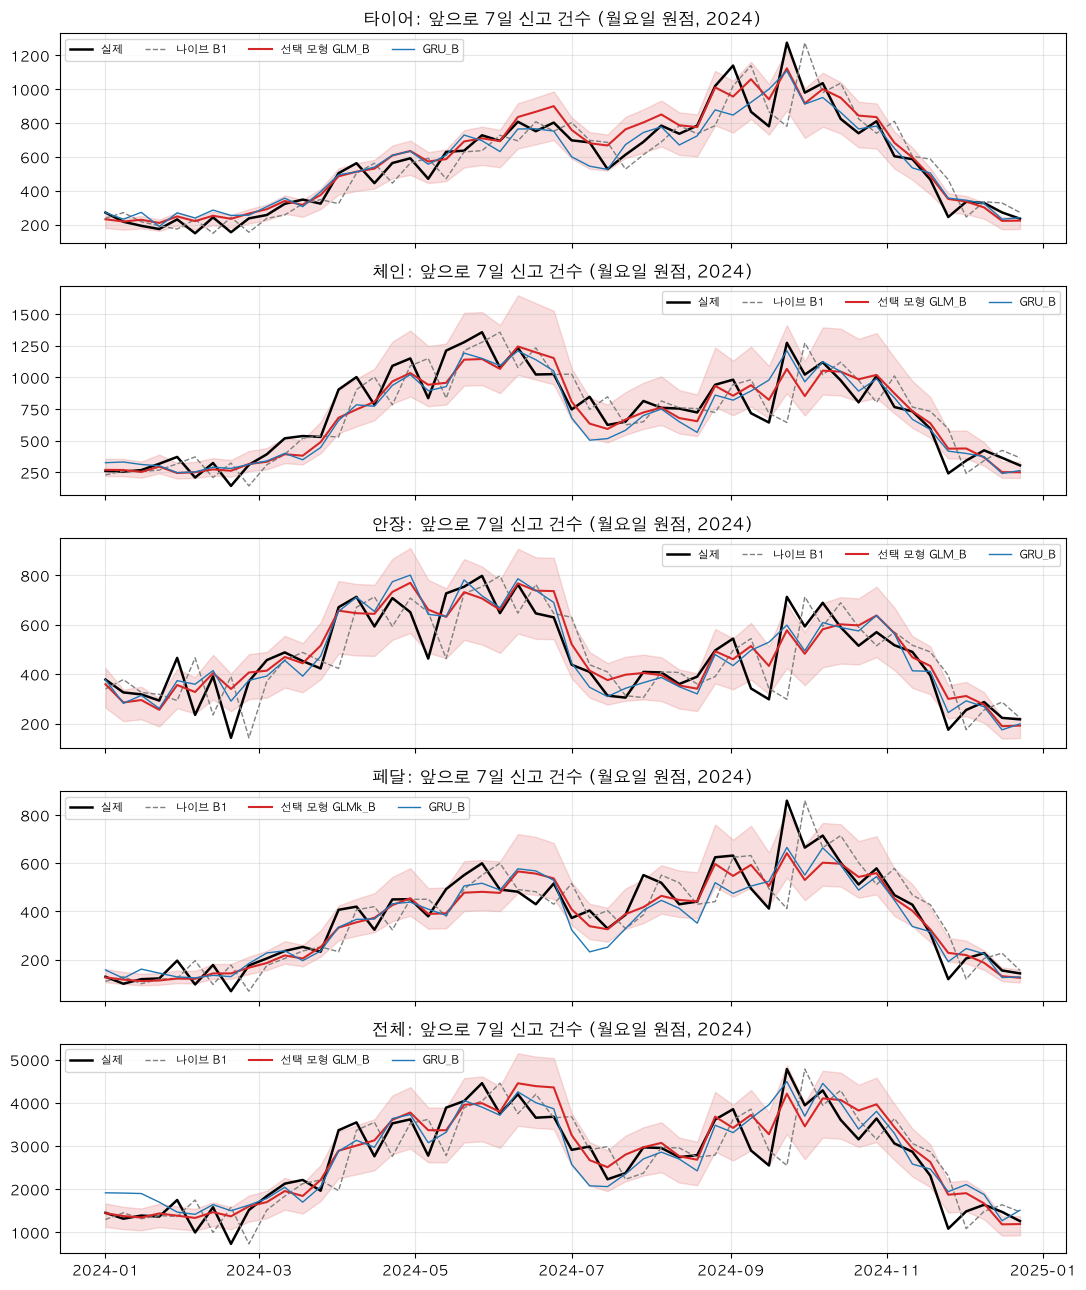

In [18]:
# 선택 모형의 검증 구간 주간 예측과 실제(월요일 원점만 이어서 그린다). 띠는 보정한 80% 구간
fig, axes = plt.subplots(len(PARTS), 1, figsize=(11, 2.6 * len(PARTS)), sharex=True)
for ax, (part, name) in zip(axes, PARTS.items()):
    pick = sel.loc[name, "선택"]; c_ = cal[(cal.part == part) & (cal.model == pick)].iloc[0]
    a = base[(base.part == part) & (base.split == "valid") & (base.origin.dt.dayofweek == 0)].set_index("origin")
    p = valid_preds[(valid_preds.part == part) & (valid_preds.model == pick) & (valid_preds.origin.dt.dayofweek == 0)].set_index("origin")
    g = valid_preds[(valid_preds.part == part) & (valid_preds.model == "GRU_B") & (valid_preds.origin.dt.dayofweek == 0)].set_index("origin")
    ax.plot(a.index, a.y, color="black", lw=1.8, label="실제")
    ax.plot(a.index, a.B1, color="gray", lw=1, ls="--", label="나이브 B1")
    ax.plot(p.index, p.pred, color="tab:red", lw=1.5, label=f"선택 모형 {pick}")
    ax.fill_between(p.index, p.pred * (1 + c_.r_lo), p.pred * (1 + c_.r_hi), color="tab:red", alpha=0.15)
    ax.plot(g.index, g.pred, color="tab:blue", lw=1, label="GRU_B")
    ax.set_title(f"{name}: 앞으로 7일 신고 건수 (월요일 원점, 2024)"); ax.grid(alpha=0.3); ax.legend(ncol=4, fontsize=8)
plt.tight_layout(); plt.savefig(ROOT / "output/figures/fc_valid_selected.png", dpi=200, bbox_inches="tight"); plt.show()

## 다음에 할 일

**테스트 구간(2025-01-01 ~ 2026-06-24)은 사람이 승인하기 전에는 열지 않는다.**
여는 시점: 모형에 영향을 줄 수 있는 작업이 모두 끝나고, `output/models/selection.csv`가 커밋된 뒤.

열 때 하는 일(코드는 그때 추가한다)
1. 선택 모형과 함께 보고할 모형(B1, S1, GLM, GLMk, GRU)을 학습 + 검증 원점(~ 2024-12-25)으로 다시 맞춘다.
2. 테스트 원점을 예측하고 채점한다: 부품별 skill, 2025 상반기·하반기·2026 상반기별, 편향, 월요일 원점만.
3. 보정한 80% 구간에 실제값이 든 비율을 확인한다.
4. 날씨 시나리오 A·B·C·D별 성능을 비교한다.